# Irrigation Need Prediction using XGBoost
Complete pipeline: EDA -> preprocessing -> training -> evaluation -> visuals -> `.pkl` export

**Target:** `Irrigation_Need` (Low / Medium / High) — a multi-class classification problem.

#### Imports

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

import xgboost as xgb
from xgboost import XGBClassifier


#### Config

In [4]:
DATA_PATH = "../Dataset/irrigation_prediction.csv"   # <-- update path if needed
OUT_DIR = "outputs"                        # relative folder, created next to this notebook
os.makedirs(OUT_DIR, exist_ok=True)
print("Saving all outputs to:", os.path.abspath(OUT_DIR))

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42


Saving all outputs to: c:\Users\Aakash Kavediya\OneDrive\Documents\FarmerOS\Models\irrigation_prediction\outputs


## 1. Load Data

In [5]:
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (10000, 20)


,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,Clay,6.14,36.48,0.42,2.17,21.90,31.19,1167.70,4.01,1.97,Wheat,Vegetative,Rabi,Rainfed,Reservoir,4.73,Yes,1.98,South,Low
1,Silt,6.41,50.56,0.38,0.23,36.50,26.01,831.28,10.72,16.82,Maize,Flowering,Zaid,Canal,Groundwater,12.22,Yes,33.56,Central,Medium
2,Sandy,7.71,40.07,1.09,2.18,41.83,76.41,1844.45,7.75,19.03,Cotton,Harvest,Rabi,Drip,Reservoir,5.52,Yes,34.62,South,Low
3,Clay,5.96,12.75,1.56,0.40,37.22,43.32,306.26,8.90,11.44,Wheat,Sowing,Kharif,Canal,Reservoir,1.43,Yes,84.03,North,Medium
4,Clay,7.76,18.58,0.95,2.52,22.38,86.44,1875.63,10.39,11.26,Cotton,Sowing,Zaid,Canal,River,2.52,No,60.86,South,Medium


In [6]:
print("Missing values:\n", df.isnull().sum())
print("\nTarget distribution:\n", df["Irrigation_Need"].value_counts())


Missing values:
 Soil_Type                  0
Soil_pH                    0
Soil_Moisture              0
Organic_Carbon             0
Electrical_Conductivity    0
Temperature_C              0
Humidity                   0
Rainfall_mm                0
Sunlight_Hours             0
Wind_Speed_kmh             0
Crop_Type                  0
Crop_Growth_Stage          0
Season                     0
Irrigation_Type            0
Water_Source               0
Field_Area_hectare         0
Mulching_Used              0
Previous_Irrigation_mm     0
Region                     0
Irrigation_Need            0
dtype: int64

Target distribution:
 Irrigation_Need
Low       5864
Medium    3800
High       336
Name: count, dtype: int64


In [7]:
TARGET = "Irrigation_Need"
CAT_COLS = ["Soil_Type", "Crop_Type", "Crop_Growth_Stage", "Season",
            "Irrigation_Type", "Water_Source", "Mulching_Used", "Region"]
NUM_COLS = ["Soil_pH", "Soil_Moisture", "Organic_Carbon", "Electrical_Conductivity",
            "Temperature_C", "Humidity", "Rainfall_mm", "Sunlight_Hours",
            "Wind_Speed_kmh", "Field_Area_hectare", "Previous_Irrigation_mm"]
FEATURES = CAT_COLS + NUM_COLS
print("Categorical features:", CAT_COLS)
print("Numeric features:", NUM_COLS)


Categorical features: ['Soil_Type', 'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Irrigation_Type', 'Water_Source', 'Mulching_Used', 'Region']
Numeric features: ['Soil_pH', 'Soil_Moisture', 'Organic_Carbon', 'Electrical_Conductivity', 'Temperature_C', 'Humidity', 'Rainfall_mm', 'Sunlight_Hours', 'Wind_Speed_kmh', 'Field_Area_hectare', 'Previous_Irrigation_mm']


## 2. Exploratory Data Analysis (EDA)

### 2a. Target class distribution

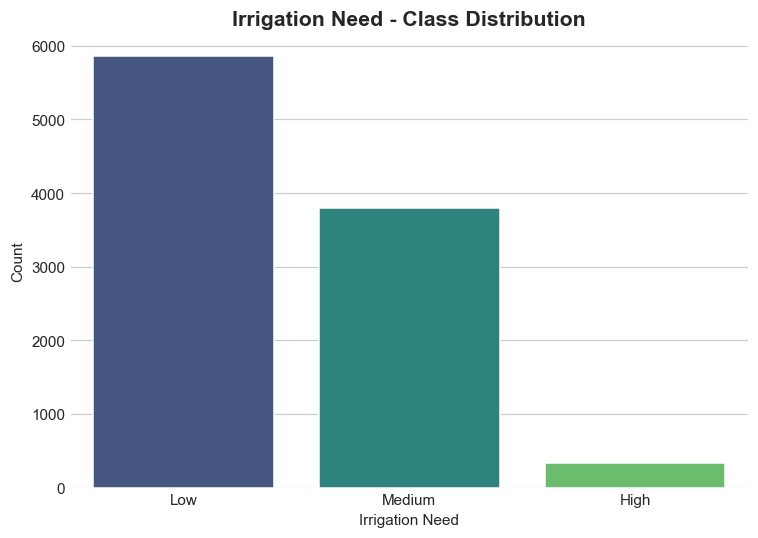

In [8]:
plt.figure(figsize=(7, 5))
order = df[TARGET].value_counts().index
sns.countplot(data=df, x=TARGET, order=order, palette="viridis")
plt.title("Irrigation Need - Class Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Irrigation Need")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/01_class_distribution.png")
plt.show()


### 2b. Numeric feature distributions

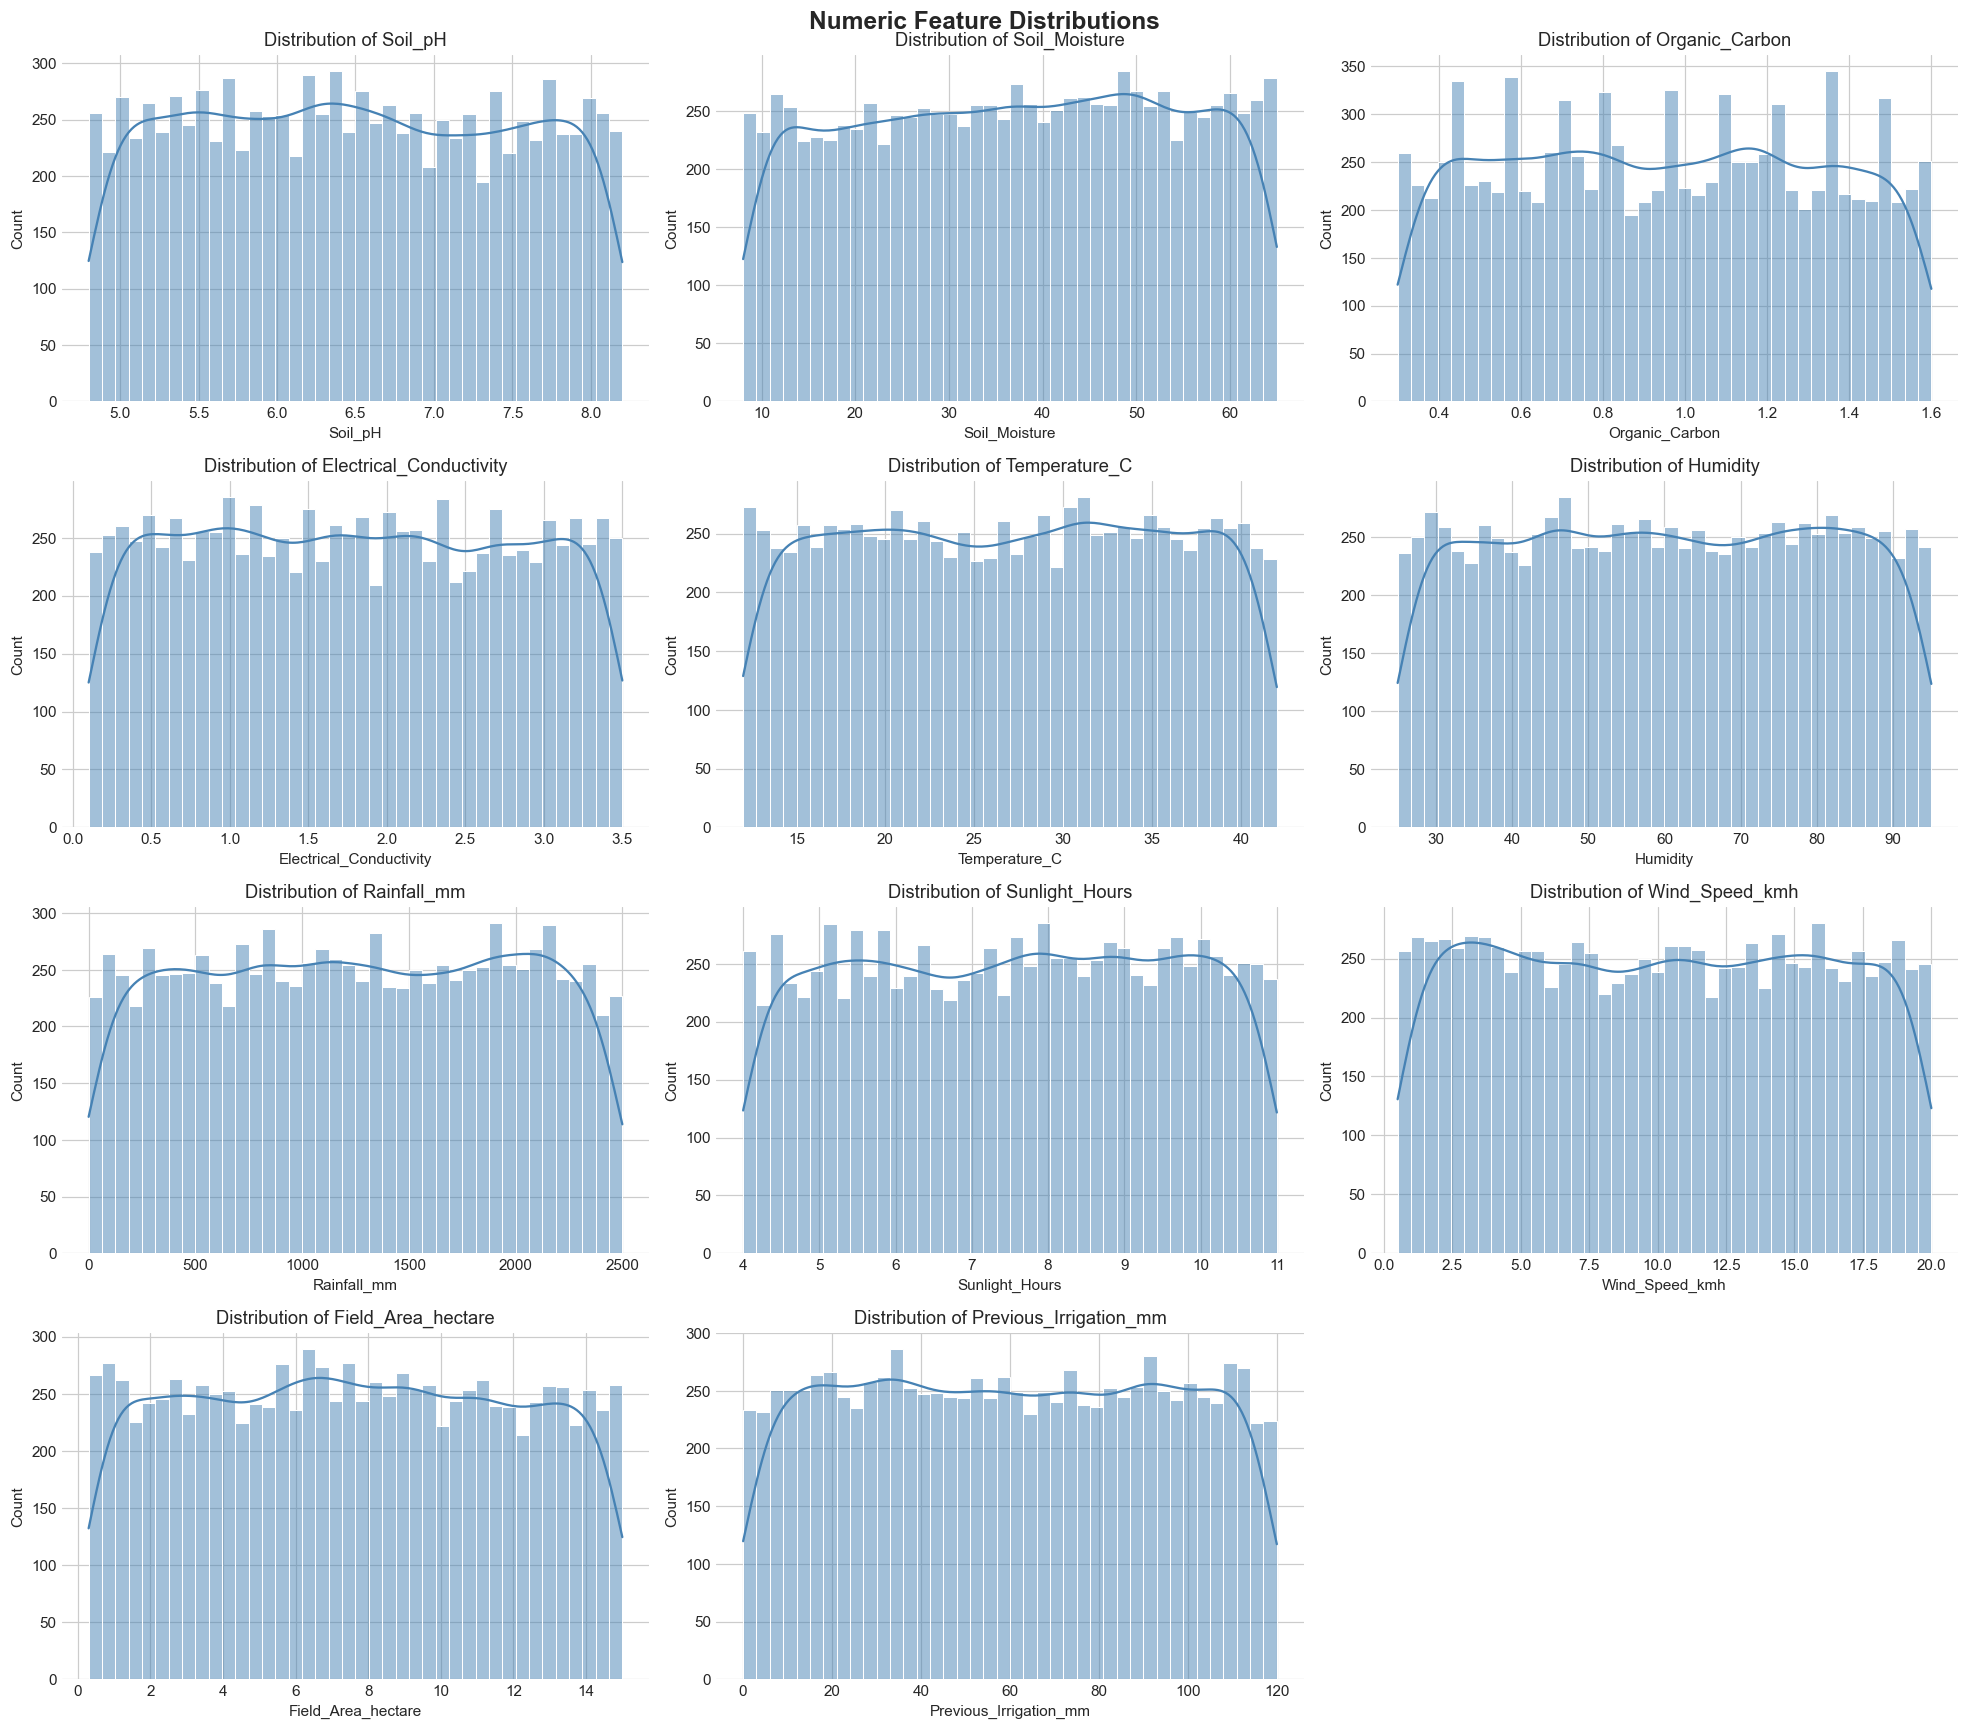

In [9]:
fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()
for i, col in enumerate(NUM_COLS):
    sns.histplot(df[col], bins=40, kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(f"Distribution of {col}")
for j in range(len(NUM_COLS), len(axes)):
    fig.delaxes(axes[j])
plt.suptitle("Numeric Feature Distributions", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02_numeric_feature_distributions.png")
plt.show()


### 2c. Categorical feature counts

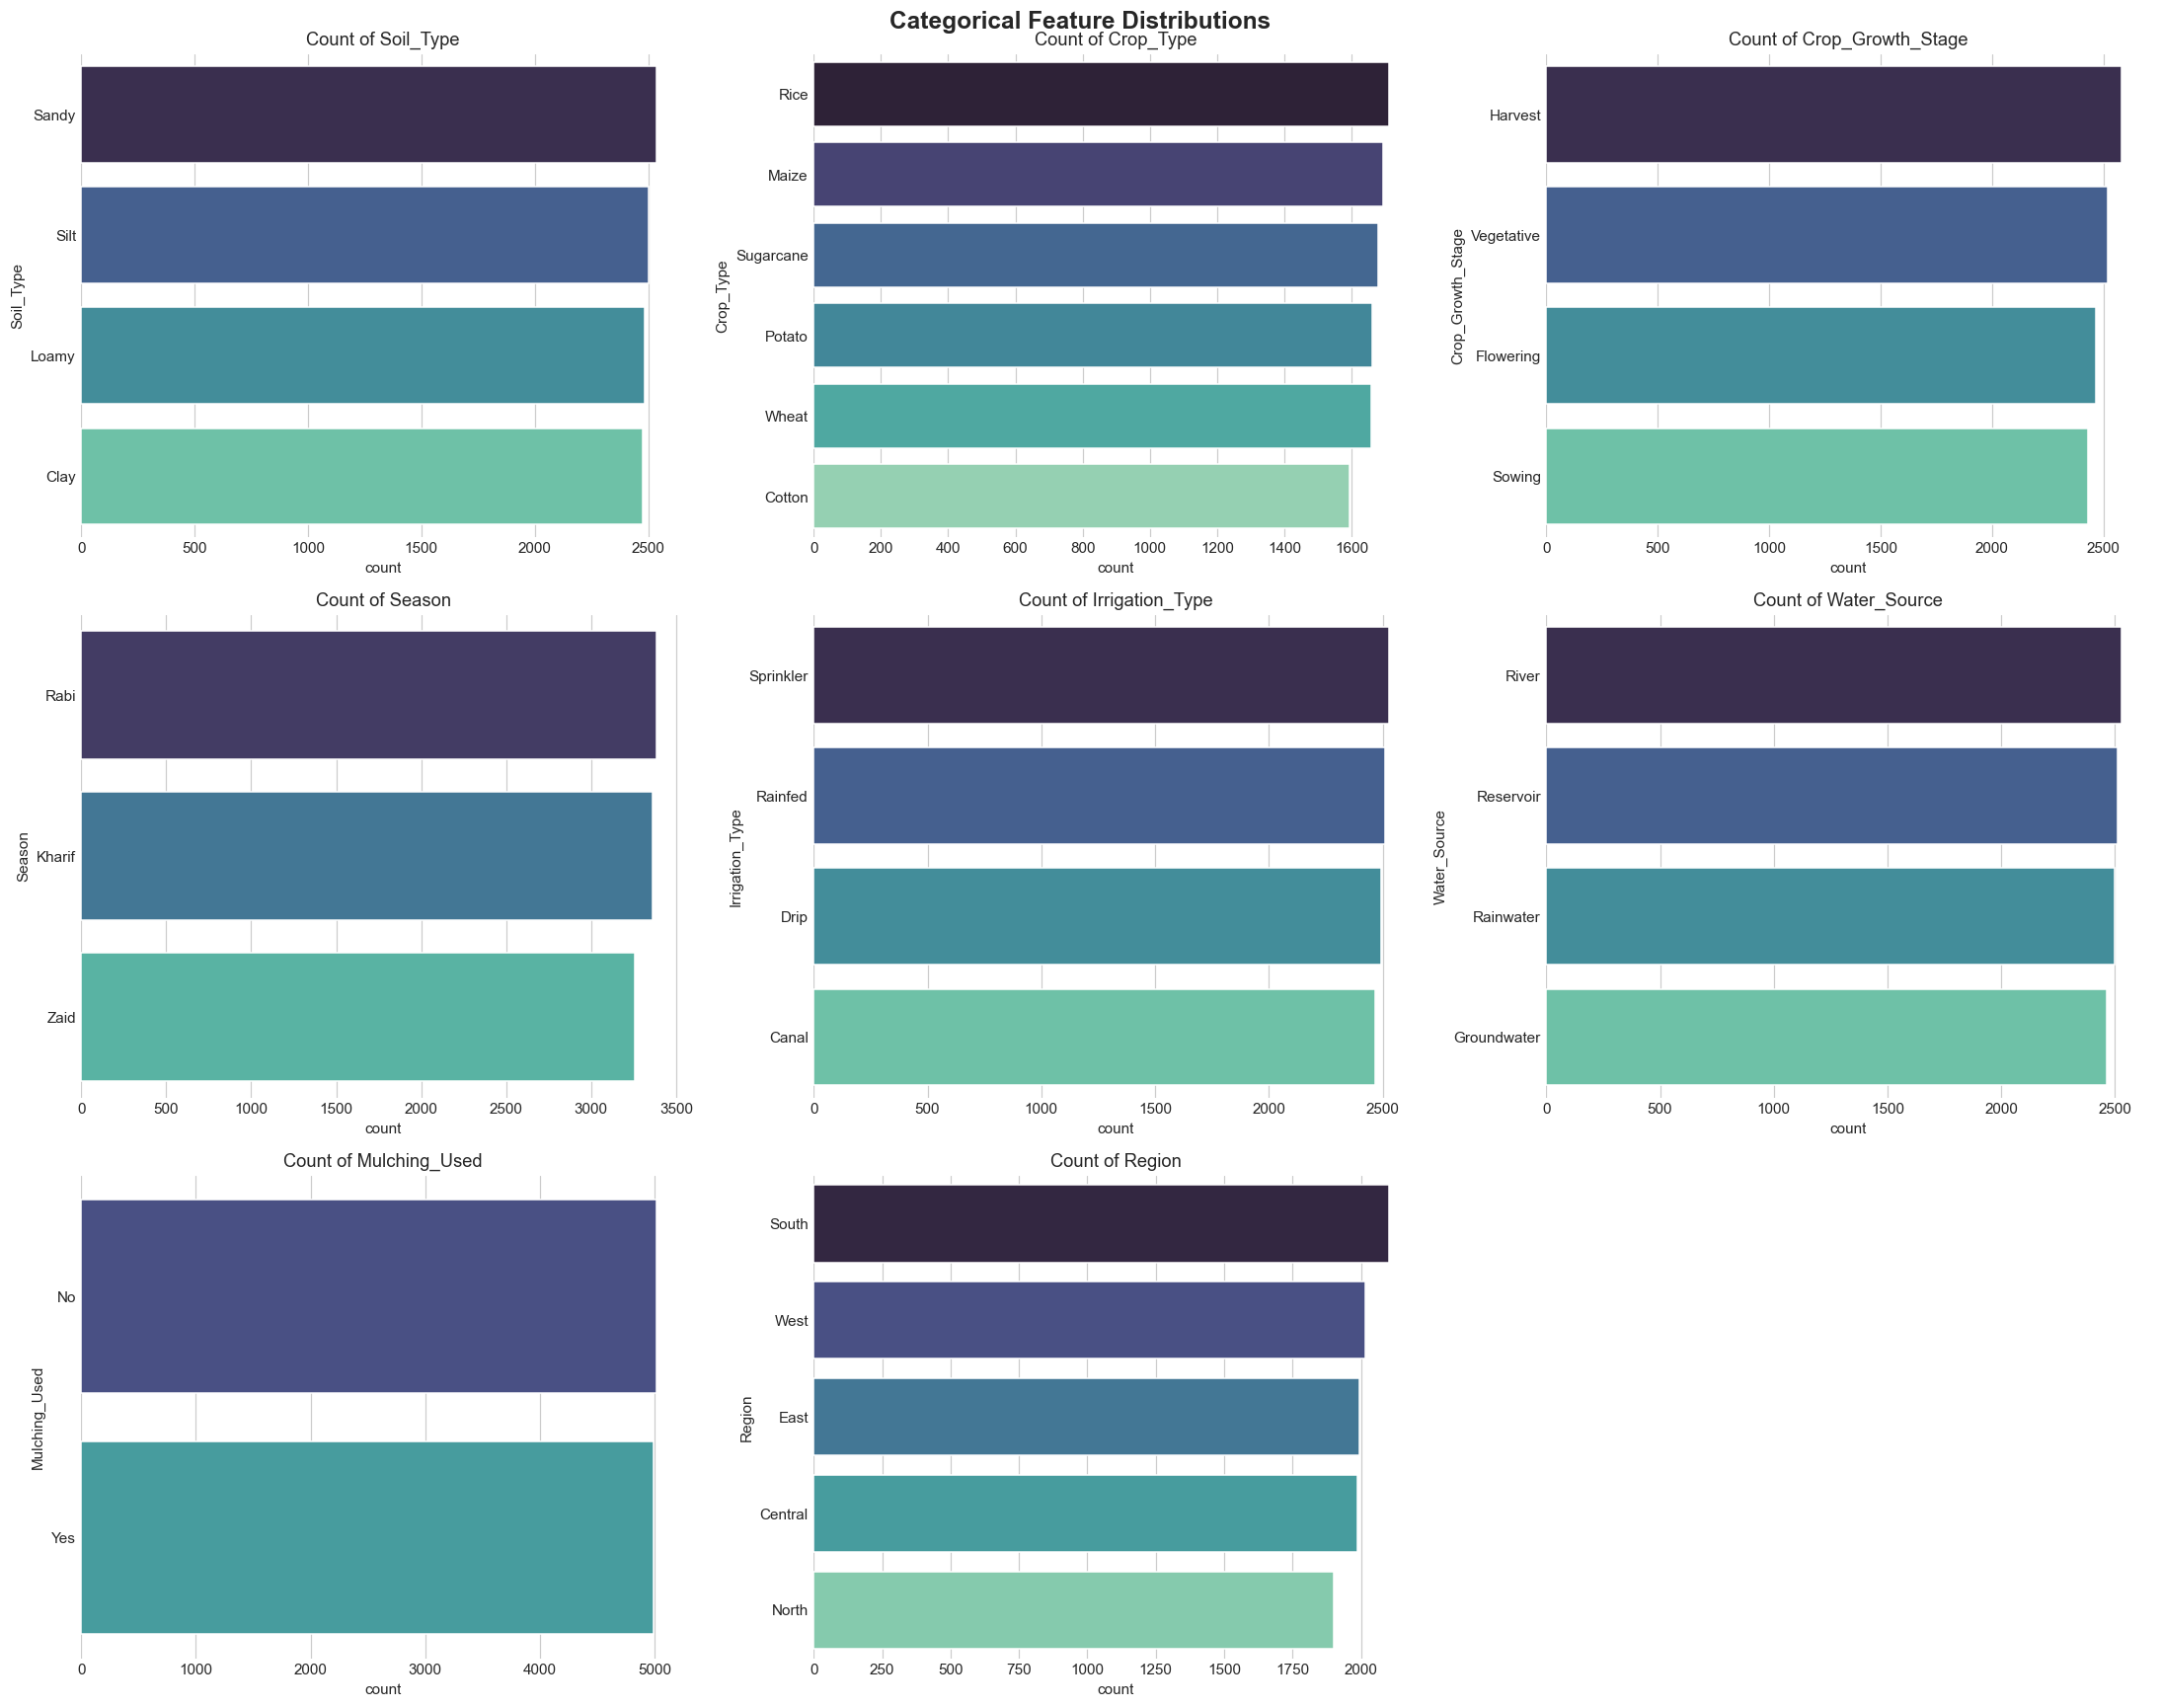

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(20, 16))
axes = axes.flatten()
for i, col in enumerate(CAT_COLS):
    sns.countplot(data=df, y=col, ax=axes[i], palette="mako",
                  order=df[col].value_counts().index)
    axes[i].set_title(f"Count of {col}")
for j in range(len(CAT_COLS), len(axes)):
    fig.delaxes(axes[j])
plt.suptitle("Categorical Feature Distributions", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/03_categorical_distributions.png")
plt.show()


### 2d. Correlation heatmap (numeric features)

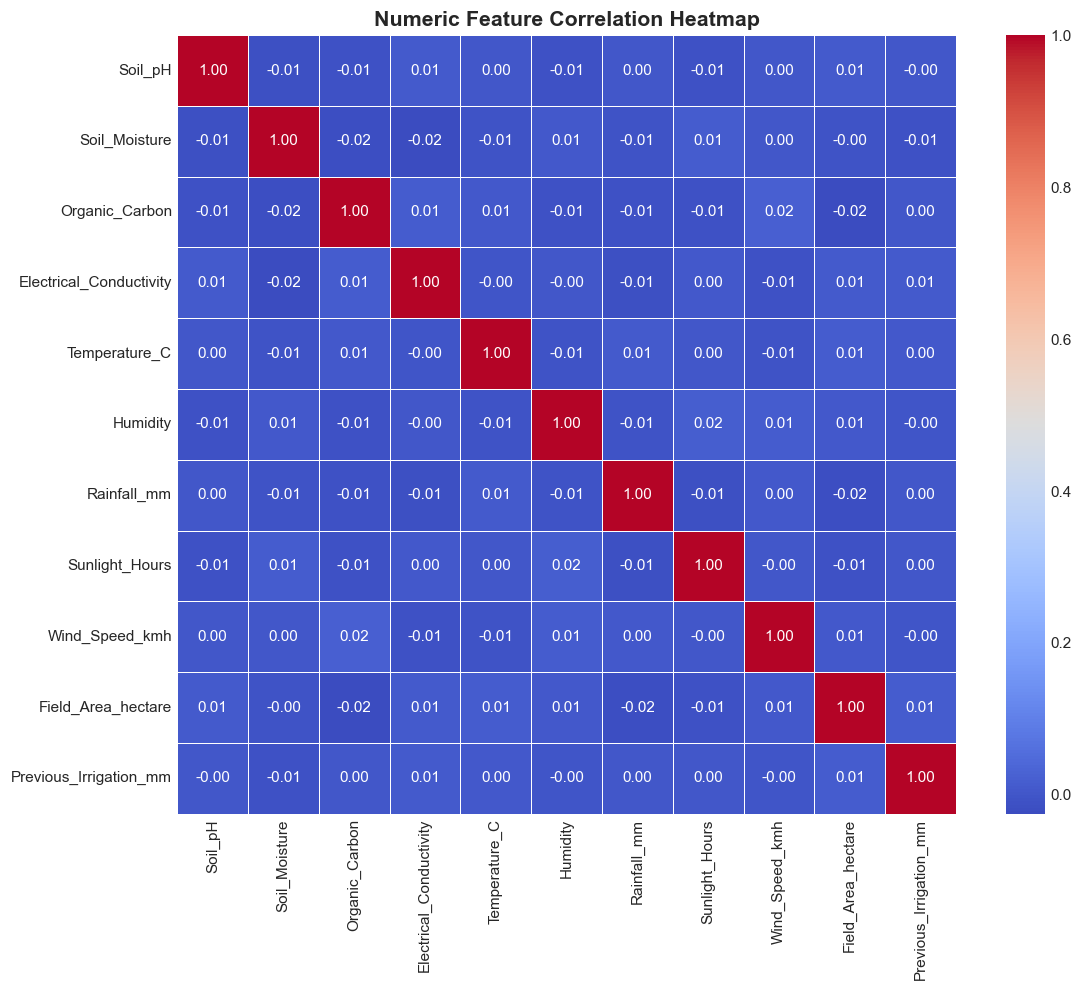

In [11]:
plt.figure(figsize=(11, 9))
corr = df[NUM_COLS].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True, linewidths=0.5)
plt.title("Numeric Feature Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_correlation_heatmap.png")
plt.show()


### 2e. Boxplots of numeric features by Irrigation Need

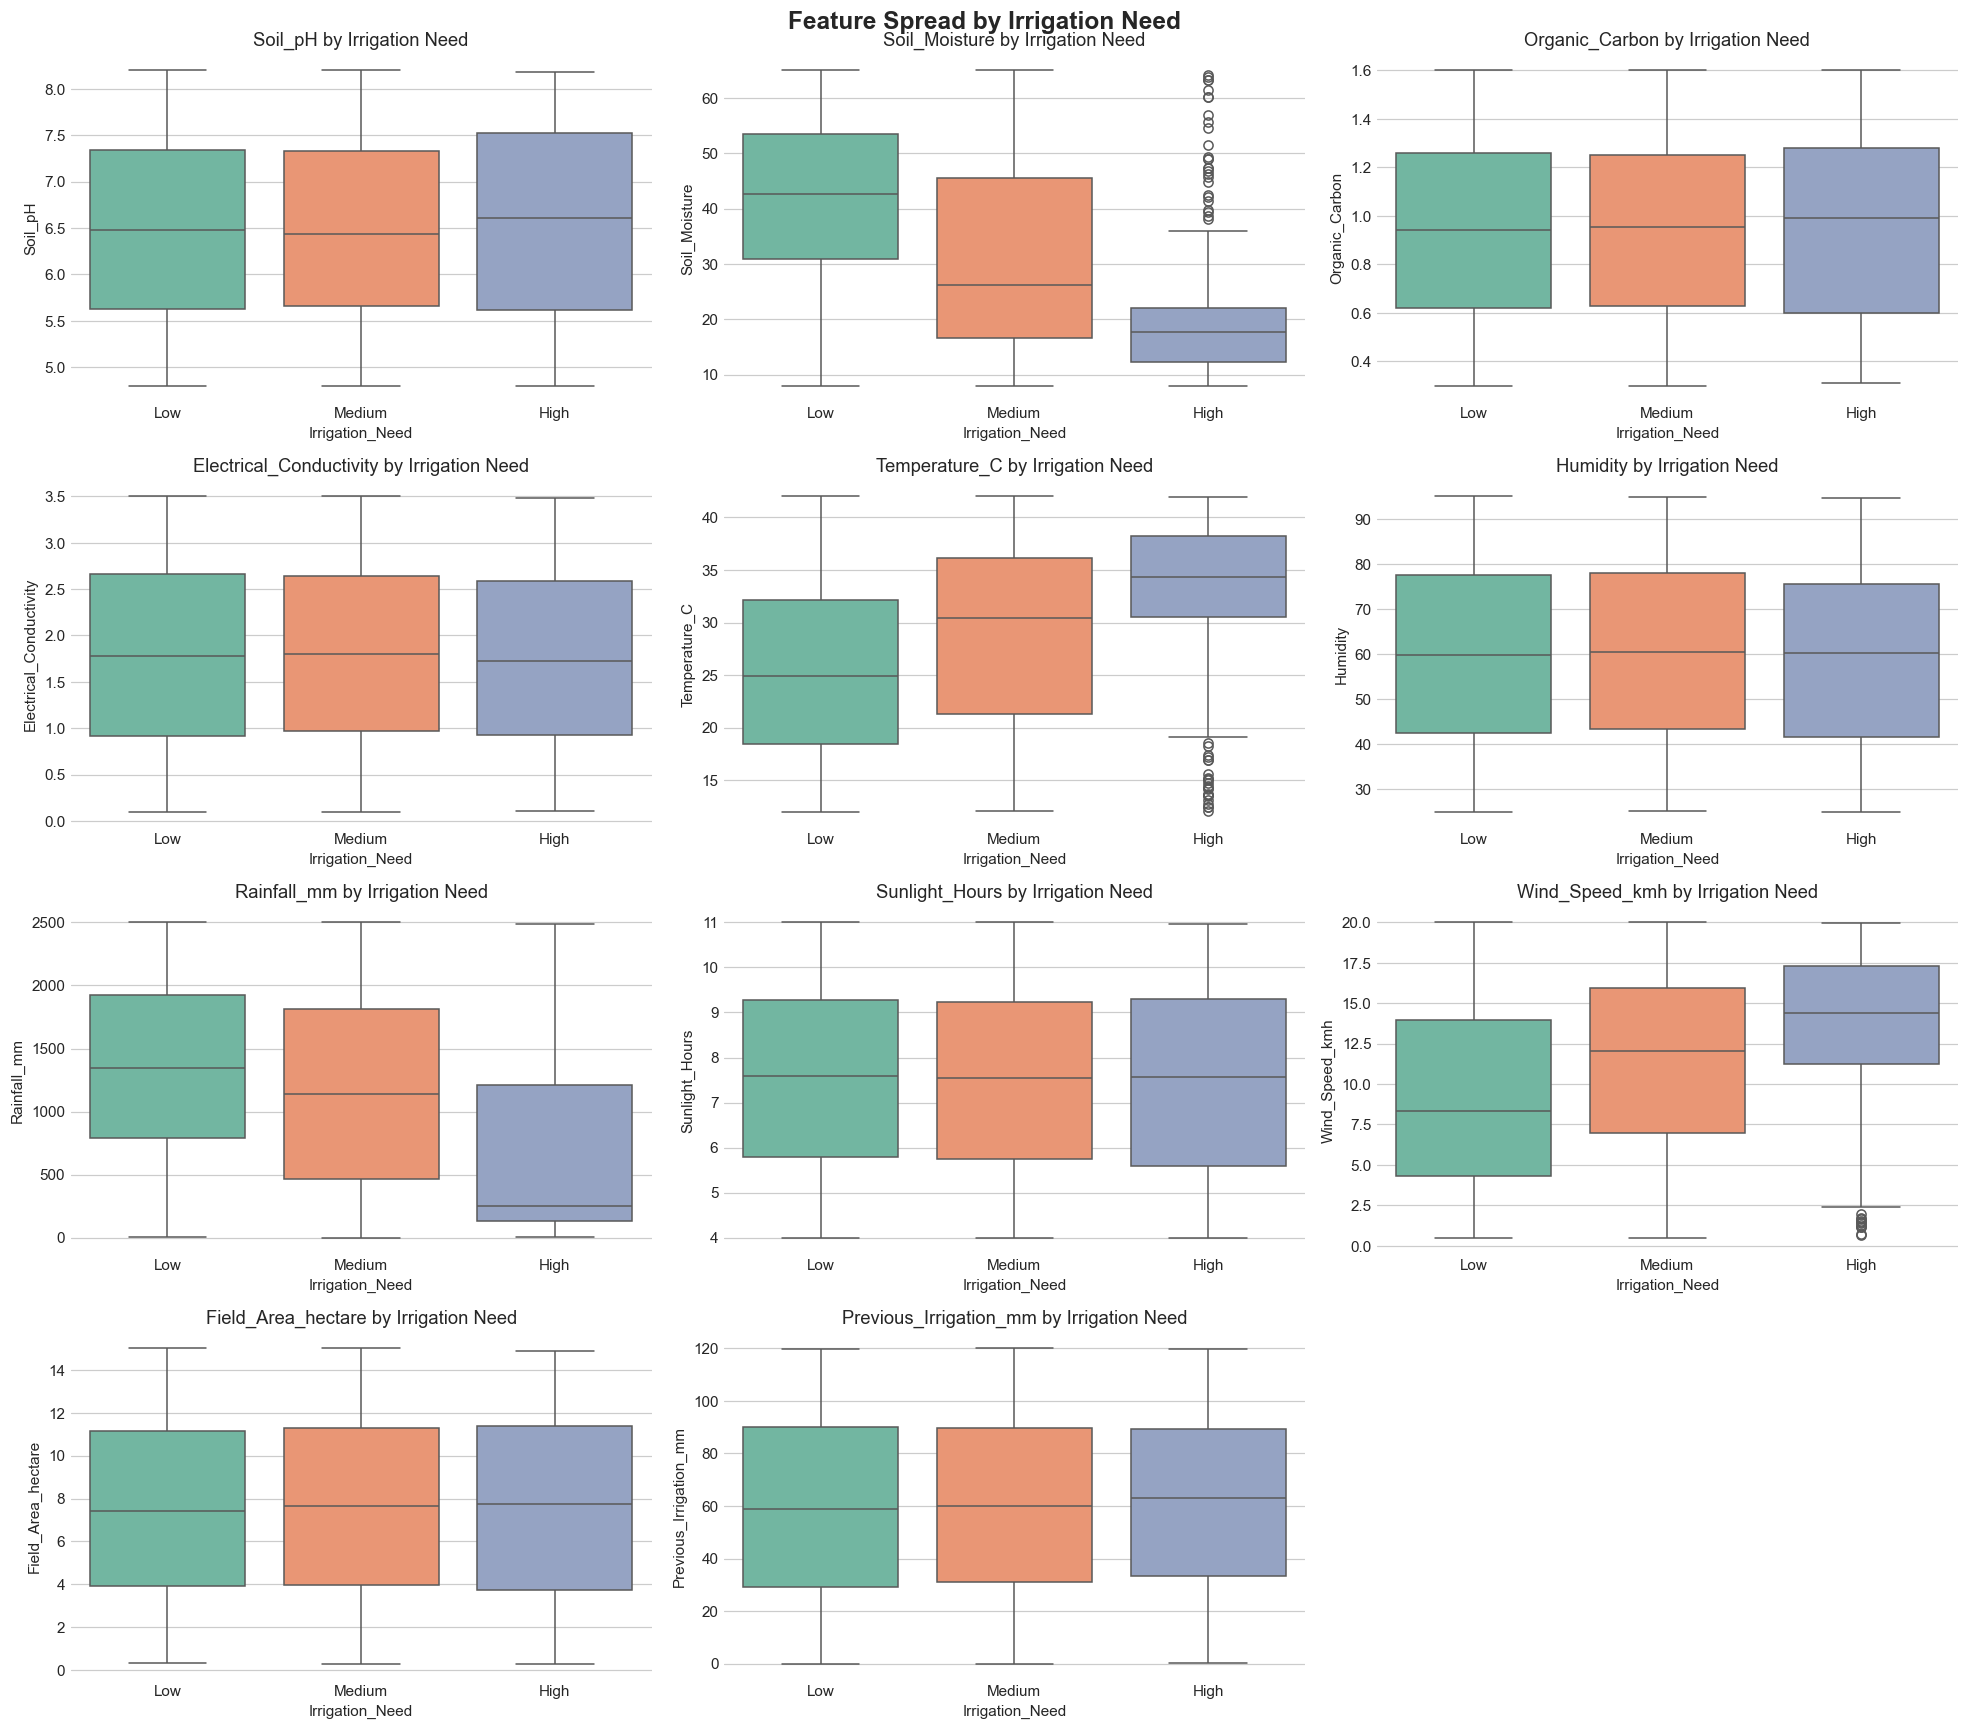

In [12]:
fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()
for i, col in enumerate(NUM_COLS):
    sns.boxplot(data=df, x=TARGET, y=col, order=order, ax=axes[i], palette="Set2")
    axes[i].set_title(f"{col} by Irrigation Need")
for j in range(len(NUM_COLS), len(axes)):
    fig.delaxes(axes[j])
plt.suptitle("Feature Spread by Irrigation Need", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/05_boxplots_by_target.png")
plt.show()


### 2f. Irrigation Need by Crop Type and Region (stacked bar)

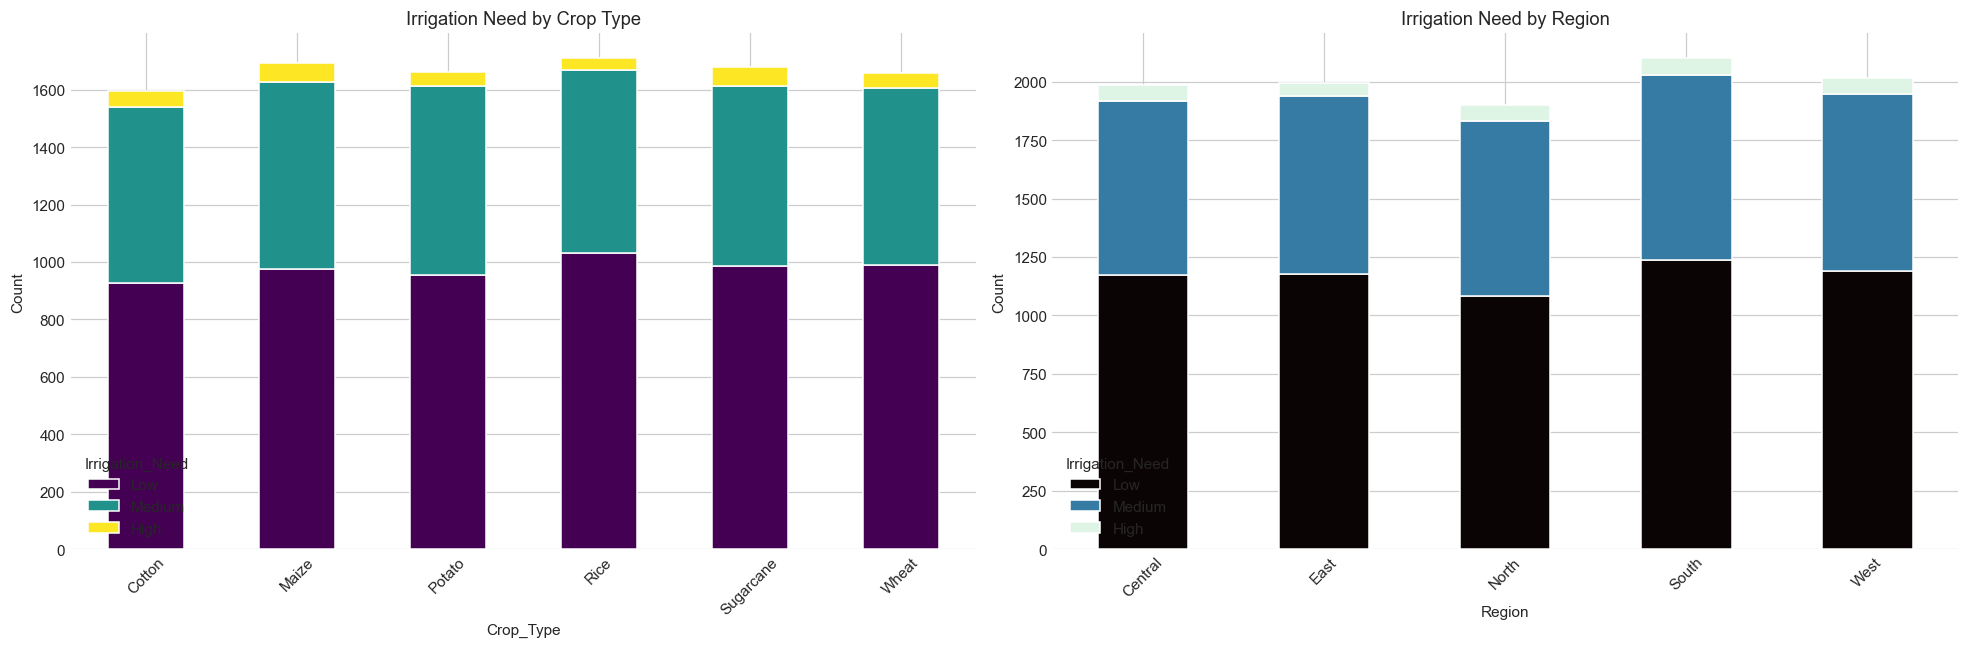

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

pd.crosstab(df["Crop_Type"], df[TARGET]).loc[:, order].plot(
    kind="bar", stacked=True, ax=axes[0], colormap="viridis"
)
axes[0].set_title("Irrigation Need by Crop Type")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)

pd.crosstab(df["Region"], df[TARGET]).loc[:, order].plot(
    kind="bar", stacked=True, ax=axes[1], colormap="mako"
)
axes[1].set_title("Irrigation Need by Region")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/06_irrigation_by_crop_region.png")
plt.show()


### 2g. Pairplot of key numeric features by target

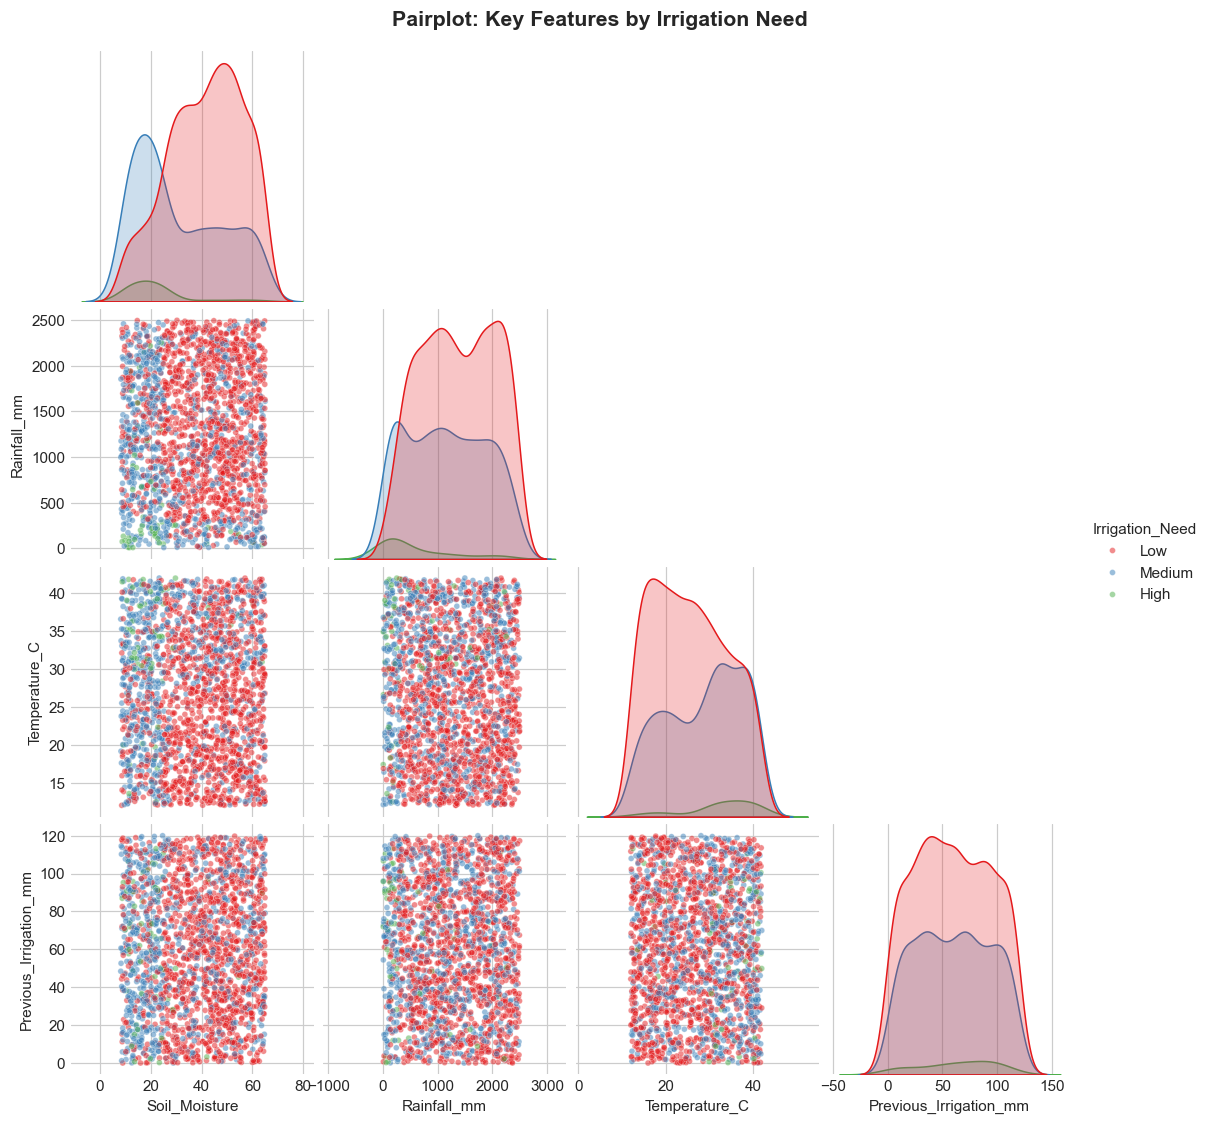

In [14]:
sample_df = df.sample(min(2000, len(df)), random_state=RANDOM_STATE)
g = sns.pairplot(sample_df, vars=["Soil_Moisture", "Rainfall_mm", "Temperature_C", "Previous_Irrigation_mm"],
                  hue=TARGET, hue_order=order, palette="Set1", plot_kws={"alpha": 0.5, "s": 15}, corner=True)
g.fig.suptitle("Pairplot: Key Features by Irrigation Need", y=1.02, fontsize=14, fontweight="bold")
g.savefig(f"{OUT_DIR}/07_pairplot.png")
plt.show()


## 3. Preprocessing

In [15]:
df_model = df.copy()

encoders = {}
for col in CAT_COLS:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    encoders[col] = le

target_encoder = LabelEncoder()
df_model[TARGET] = target_encoder.fit_transform(df_model[TARGET])
print("Target classes:", list(target_encoder.classes_), "->", list(range(len(target_encoder.classes_))))

X = df_model[FEATURES]
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")


Target classes: ['High', 'Low', 'Medium'] -> [0, 1, 2]
Train shape: (8000, 19), Test shape: (2000, 19)


## 4. Model Training - XGBoost Classifier\nClass weights are balanced via `sample_weight` since `Irrigation_Need` is imbalanced (Low >> Medium >> High).

In [16]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

xgb_clf = XGBClassifier(
    objective="multi:softprob",
    num_class=len(target_encoder.classes_),
    eval_metric="mlogloss",
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist",
)

eval_set = [(X_train, y_train), (X_test, y_test)]
xgb_clf.fit(X_train, y_train, sample_weight=sample_weights, eval_set=eval_set, verbose=False)


,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'mlogloss'


## 5. Cross Validation

In [17]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(xgb_clf, X, y, cv=skf, scoring="accuracy", n_jobs=-1)
print(f"5-Fold CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


5-Fold CV Accuracy: 0.9960 (+/- 0.0011)


## 6. Evaluation

In [18]:
y_pred = xgb_clf.predict(X_test)
y_proba = xgb_clf.predict_proba(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted")
rec = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print(f"Test Accuracy : {acc:.4f}")
print(f"Precision(wt) : {prec:.4f}")
print(f"Recall(wt)    : {rec:.4f}")
print(f"F1-score(wt)  : {f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=target_encoder.classes_))


Test Accuracy : 0.9975
Precision(wt) : 0.9975
Recall(wt)    : 0.9975
F1-score(wt)  : 0.9975

Classification Report:

              precision    recall  f1-score   support

        High       1.00      0.94      0.97        67
         Low       1.00      1.00      1.00      1173
      Medium       0.99      1.00      1.00       760

    accuracy                           1.00      2000
   macro avg       1.00      0.98      0.99      2000
weighted avg       1.00      1.00      1.00      2000



## 7. Visualizations - Model Performance

### 7a. Confusion Matrix

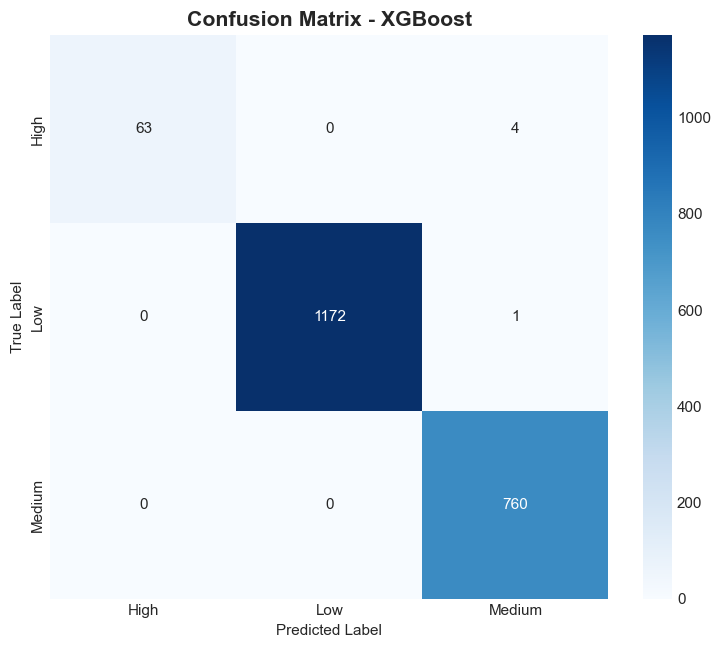

In [19]:
plt.figure(figsize=(7, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_encoder.classes_, yticklabels=target_encoder.classes_)
plt.title("Confusion Matrix - XGBoost", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/08_confusion_matrix.png")
plt.show()


### 7b. Feature Importance (weight / gain / cover)

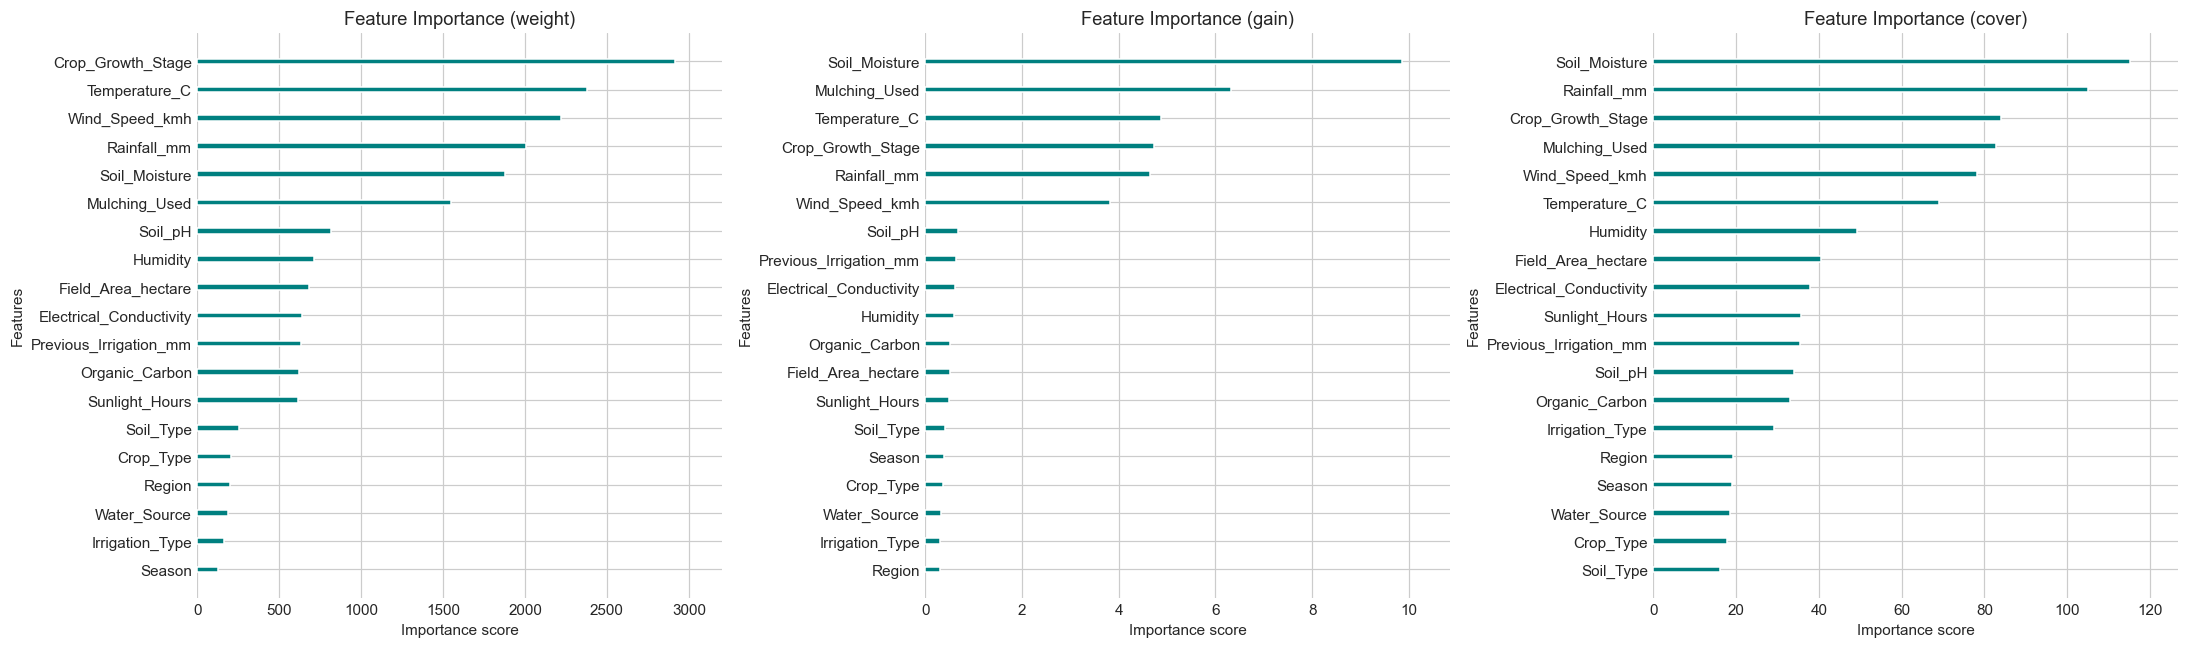

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
importance_types = ["weight", "gain", "cover"]
for ax, imp_type in zip(axes, importance_types):
    xgb.plot_importance(xgb_clf, importance_type=imp_type, ax=ax,
                         title=f"Feature Importance ({imp_type})",
                         color="teal", show_values=False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/09_feature_importance.png")
plt.show()


### 7c. Training vs Validation loss curve

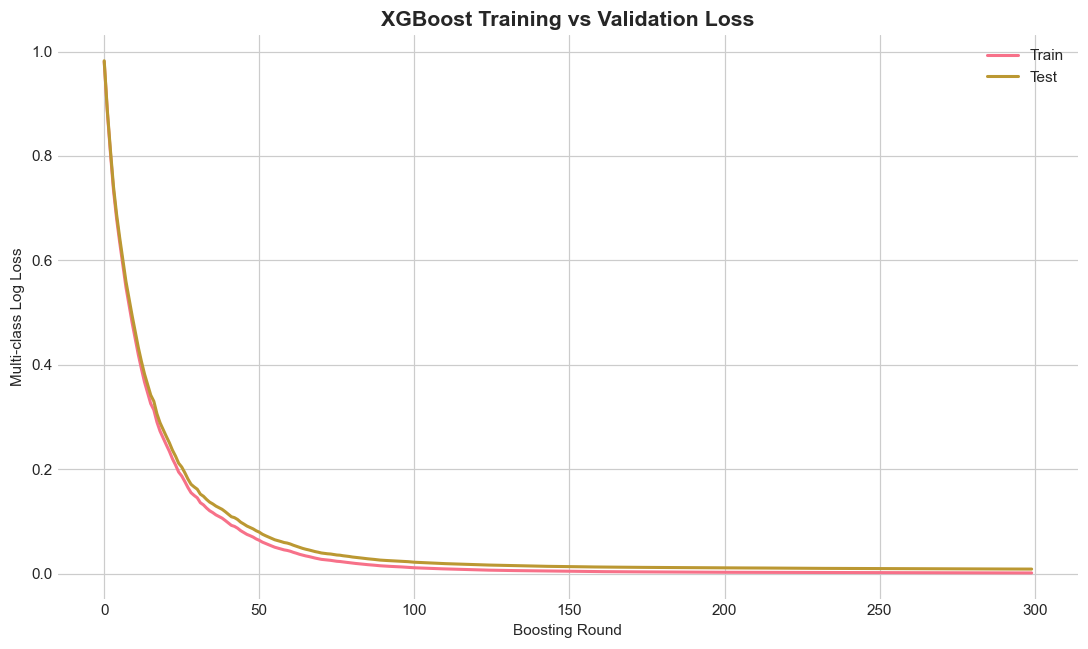

In [21]:
results = xgb_clf.evals_result()
epochs = len(results["validation_0"]["mlogloss"])
x_axis = range(epochs)
plt.figure(figsize=(10, 6))
plt.plot(x_axis, results["validation_0"]["mlogloss"], label="Train", linewidth=2)
plt.plot(x_axis, results["validation_1"]["mlogloss"], label="Test", linewidth=2)
plt.xlabel("Boosting Round")
plt.ylabel("Multi-class Log Loss")
plt.title("XGBoost Training vs Validation Loss", fontsize=14, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/10_training_curve.png")
plt.show()


### 7d. ROC Curves (One-vs-Rest, multi-class)

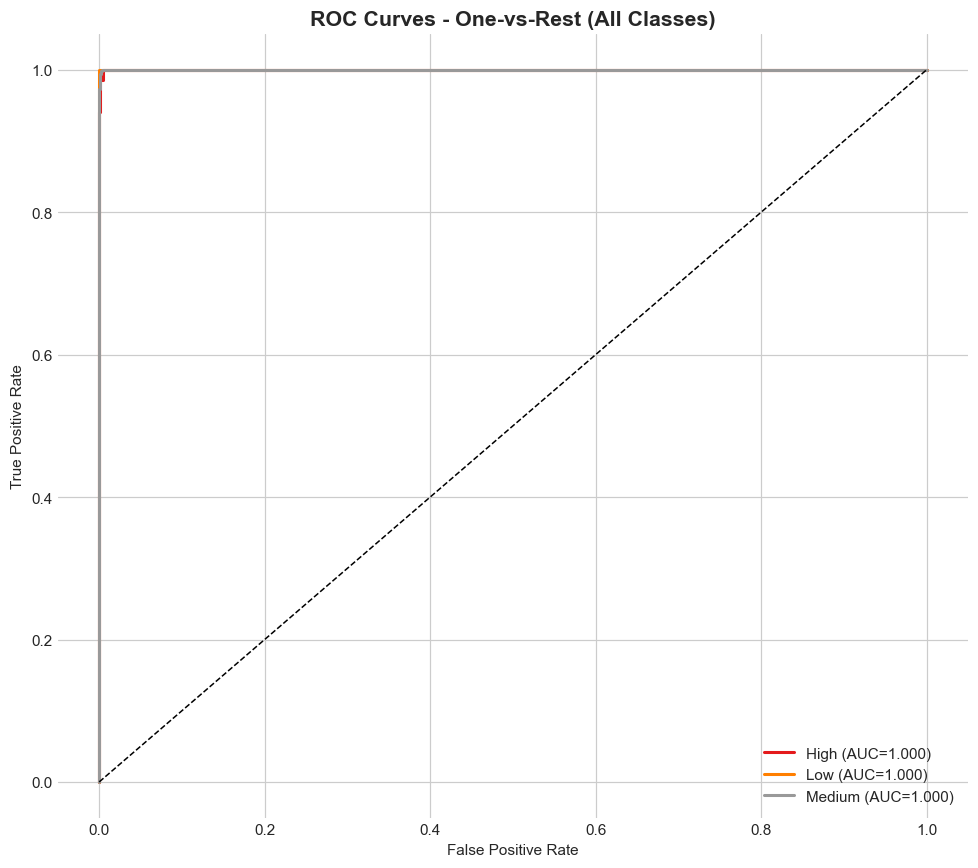

In [22]:
y_test_bin = label_binarize(y_test, classes=range(len(target_encoder.classes_)))
n_classes = y_test_bin.shape[1]

fpr, tpr, roc_auc = {}, {}, {}
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(9, 8))
colors = plt.cm.Set1(np.linspace(0, 1, n_classes))
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
              label=f"{target_encoder.classes_[i]} (AUC={roc_auc[i]:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - One-vs-Rest (All Classes)", fontsize=14, fontweight="bold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/11_roc_curves.png")
plt.show()


### 7e. Per-class Precision / Recall / F1

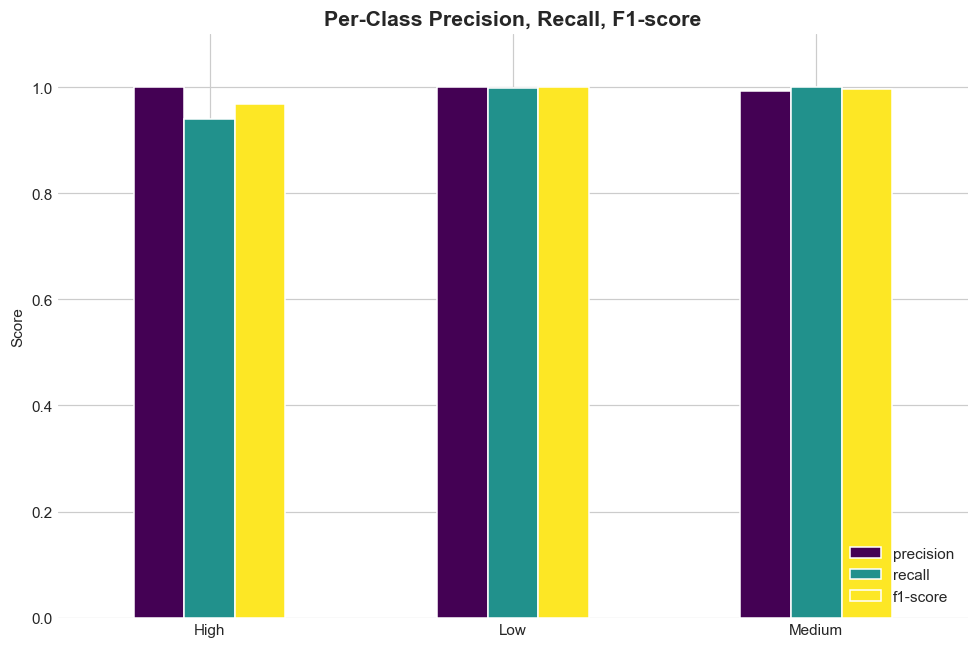

In [23]:
report_dict = classification_report(y_test, y_pred, target_names=target_encoder.classes_, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose().iloc[:-3]
report_df[["precision", "recall", "f1-score"]].plot(kind="bar", figsize=(9, 6), colormap="viridis")
plt.title("Per-Class Precision, Recall, F1-score", fontsize=14, fontweight="bold")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/12_per_class_metrics.png")
plt.show()


### 7f. Cross-validation score distribution

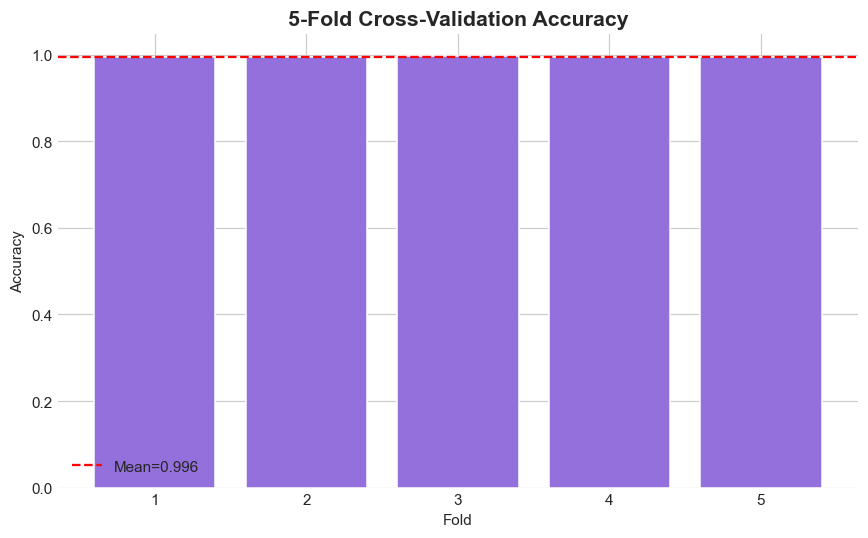

In [24]:
plt.figure(figsize=(8, 5))
plt.bar(range(1, len(cv_scores) + 1), cv_scores, color="mediumpurple")
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"Mean={cv_scores.mean():.3f}")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("5-Fold Cross-Validation Accuracy", fontsize=14, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/13_cv_scores.png")
plt.show()


## 8. Save Model + Artifacts (`.pkl`)

In [25]:
with open(f"{OUT_DIR}/xgboost_irrigation_model.pkl", "wb") as f:
    pickle.dump(xgb_clf, f)

with open(f"{OUT_DIR}/label_encoders.pkl", "wb") as f:
    pickle.dump(encoders, f)

with open(f"{OUT_DIR}/target_encoder.pkl", "wb") as f:
    pickle.dump(target_encoder, f)

print("Model saved at:", os.path.abspath(f"{OUT_DIR}/xgboost_irrigation_model.pkl"))
print("Feature label encoders saved at:", os.path.abspath(f"{OUT_DIR}/label_encoders.pkl"))
print("Target encoder saved at:", os.path.abspath(f"{OUT_DIR}/target_encoder.pkl"))

print("\nDone! Summary:")
print(f"  Test Accuracy: {acc:.4f}")
print(f"  CV Accuracy:   {cv_scores.mean():.4f}")


Model saved at: c:\Users\Aakash Kavediya\OneDrive\Documents\FarmerOS\Models\irrigation_prediction\outputs\xgboost_irrigation_model.pkl
Feature label encoders saved at: c:\Users\Aakash Kavediya\OneDrive\Documents\FarmerOS\Models\irrigation_prediction\outputs\label_encoders.pkl
Target encoder saved at: c:\Users\Aakash Kavediya\OneDrive\Documents\FarmerOS\Models\irrigation_prediction\outputs\target_encoder.pkl

Done! Summary:
  Test Accuracy: 0.9975
  CV Accuracy:   0.9960
